# Drones Ukraine v2 : 2. Classification supervisée

Objectif : reconnaître, à partir d'une piste radar, **le rôle** du drone (frappe longue portée, leurre, munition rôdeuse, reconnaissance), **son origine** (Russie ou Ukraine) et **son modèle exact** (12 classes), en comparant neuf algorithmes d'apprentissage à deux références naïves.

## Règles suivies contre la fuite de données, le sur-apprentissage et les conclusions non fondées

1. **Unité statistique = la piste radar**, jamais le point : les plots d'une même piste ne sont pas indépendants.
2. **Variables calculées uniquement sur les plots observés** (bruités, fragmentés), jamais sur la vérité du simulateur. Une garde (`verifier_absence_de_fuite`) refuse toute colonne interdite.
3. **Jeu de test temporel mis de côté** : les 30 derniers jours, jamais utilisés pour choisir un modèle ou un hyperparamètre.
4. **Validation croisée groupée par jour** (`StratifiedGroupKFold`) : les drones d'un même raid partagent route, vent et horaires ; les répartir entre plis gonflerait les scores.
5. **Pipelines** : imputation et normalisation ajustées dans chaque pli, sur les seules données d'apprentissage.
6. **Sélection du modèle sur la validation croisée**, évaluation unique sur le test, intervalles de confiance par bootstrap des jours de test.
7. **Références naïves** (classe majoritaire, tirage stratifié) et **test de permutation des étiquettes** : un modèle utile doit dépasser nettement le hasard.
8. **Diagnostics de sur-apprentissage** : courbes d'apprentissage et de validation, écart entre apprentissage et validation.
9. **Robustesse** : classification précoce, radar dégradé, secteur géographique jamais vu.
10. **Chiffres vérifiables** : tous les résultats affichés sont calculés dans ce notebook ; ils valent pour ce simulateur, pas pour le terrain.

Durée d'exécution : environ 45 minutes sur 4 cœurs (`RAPIDE = True` pour une version courte).

In [1]:
import sys
import warnings
from pathlib import Path

# Le notebook s'exécute depuis le dossier v2 (ou depuis la racine du dépôt).
RACINE_V2 = Path.cwd() if (Path.cwd() / "drone_v2").exists() else Path.cwd() / "v2"
sys.path.insert(0, str(RACINE_V2))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from drone_v2 import config, viz

viz.appliquer_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
%matplotlib inline
import json

from sklearn.metrics import classification_report, confusion_matrix, f1_score

from drone_v2 import donnees, ml
from drone_v2 import experiences as xp
from drone_v2.geo import Theatre
from drone_v2.variables import FAMILLES, VARIABLES, verifier_absence_de_fuite

RAPIDE = False  # True : moins de tirages d'hyperparamètres, de permutations et d'horizons

tables = donnees.charger_tables()
variables, pistes = tables["variables"], tables["pistes"]
LIB = {c: ml.CIBLES[c].split(" (")[0] for c in ml.CIBLES}
print(f"{len(variables)} pistes, {len(VARIABLES)} variables explicatives")

7558 pistes, 42 variables explicatives


## 1. Cibles et équilibre des classes

In [2]:
for cible, lib in ml.CIBLES.items():
    n = variables[cible].value_counts()
    print(f"{lib} : {n.size} classes, effectifs de {n.min()} à {n.max()} pistes")
display(variables.groupby(["role", "origine"]).size().unstack(fill_value=0))

Rôle (frappe, leurre, munition rôdeuse, reconnaissance) : 4 classes, effectifs de 1040 à 2678 pistes
Origine (Russie ou Ukraine) : 2 classes, effectifs de 2548 à 5010 pistes
Modèle exact (12 classes) : 12 classes, effectifs de 195 à 1951 pistes


origine,Russie,Ukraine
role,,
Frappe longue portée,1951,727
Leurre,1385,0
Munition rôdeuse,598,442
Reconnaissance,1076,1379


## 2. Découpage et contrôles anti-fuite

Apprentissage : jours 0 à 89. Test : jours 90 à 119. Les contrôles vérifient qu'aucun jour, raid, groupe de vol, drone ou piste n'apparaît des deux côtés, et que la garde refuse une colonne d'étiquette glissée par erreur dans les variables.

In [3]:
train, test = ml.decouper(variables)
print(f"Apprentissage : {len(train)} pistes (jours {train.jour.min()} à {train.jour.max()})")
print(f"Test          : {len(test)} pistes (jours {test.jour.min()} à {test.jour.max()})")
display(ml.controler_decoupage(train, test))
identiques = pd.merge(train[VARIABLES].round(6), test[VARIABLES].round(6), how="inner")
print(f"Lignes de variables identiques entre apprentissage et test : {len(identiques)}")
try:
    verifier_absence_de_fuite(VARIABLES + ["modele"])
except ValueError as erreur:
    print(f"Garde anti-fuite active : {erreur}")

Apprentissage : 5696 pistes (jours 0 à 89)
Test          : 1862 pistes (jours 90 à 119)


,identifiant,en_commun
0,jour,0
1,raid_id,0
2,groupe_id,0
3,drone_id,0
4,piste_id,0


Lignes de variables identiques entre apprentissage et test : 0
Garde anti-fuite active : Colonnes interdites dans X : ['modele']


## 3. Comparaison des algorithmes

Pour chaque cible, deux références naïves et neuf algorithmes : régression logistique, k plus proches voisins, SVM à noyau gaussien, Random Forest, Extra Trees, HistGradientBoosting, XGBoost, LightGBM et un perceptron multicouche. Les hyperparamètres sont tirés par recherche aléatoire en validation croisée groupée (score : F1 macro, qui donne le même poids à chaque classe). Le modèle retenu est celui qui obtient le meilleur score de **validation croisée** ; le test ne sert qu'à mesurer.

In [4]:
resultats, modeles, encodeurs, choisis = {}, {}, {}, {}
for cible in ml.CIBLES:
    print(f"\n{ml.CIBLES[cible]}")
    res, mods, enc = ml.comparer_modeles(train, test, cible, n_iter_max=3 if RAPIDE else None)
    y_test = enc.transform(test[cible])
    ic = [ml.bootstrap_groupe(y_test, mods[nom].predict(test[VARIABLES]), test.jour.to_numpy(), ml.f1_macro)
          for nom in res.modele]
    res["ic_bas"], res["ic_haut"] = [a for a, _ in ic], [b for _, b in ic]
    resultats[cible], modeles[cible], encodeurs[cible] = res, mods, enc
    choisis[cible] = ml.choisir(res)
    res.to_csv(config.RAPPORTS / f"comparaison_modeles_{cible}_v2.csv", index=False)
    print(f"Modèle retenu (meilleure validation croisée) : {choisis[cible]}")


Rôle (frappe, leurre, munition rôdeuse, reconnaissance)


Baseline (classe majoritaire)    CV 0.133 ± 0.003 | test 0.122 (0 s)


Baseline (tirage stratifié)      CV 0.257 ± 0.010 | test 0.248 (0 s)


Régression logistique            CV 0.940 ± 0.011 | test 0.951 (7 s)


k plus proches voisins           CV 0.948 ± 0.011 | test 0.946 (5 s)


...

HistGradientBoosting             CV 0.770 ± 0.013 | test 0.721 (291 s)


XGBoost                          CV 0.775 ± 0.018 | test 0.741 (128 s)


LightGBM                         CV 0.773 ± 0.009 | test 0.739 (149 s)


Réseau de neurones (MLP)         CV 0.724 ± 0.008 | test 0.686 (20 s)


Modèle retenu (meilleure validation croisée) : XGBoost


**Rôle (frappe, leurre, munition rôdeuse, reconnaissance)** (tri par validation croisée)

,modele,f1_cv,f1_cv_ecart_type,f1_apprentissage,f1_test,ic_bas,ic_haut,exactitude_equilibree_test,log_loss_test,auc_test,duree_s
0,LightGBM,0.963,0.011,1.000,0.965,0.953,0.976,0.967,0.094,0.998,66.153
1,HistGradientBoosting,0.961,0.009,1.000,0.967,0.955,0.978,0.970,0.119,0.998,200.809
2,XGBoost,0.961,0.010,0.998,0.967,0.955,0.978,0.970,0.085,0.998,50.251
3,Extra Trees,0.957,0.014,1.000,0.965,0.952,0.977,0.966,0.107,0.998,47.335
4,Random Forest,0.956,0.012,1.000,0.964,0.951,0.976,0.967,0.115,0.998,207.483
5,SVM (noyau RBF),0.951,0.012,0.968,0.954,0.940,0.966,0.961,0.102,0.998,29.298
6,k plus proches voisins,0.948,0.011,1.000,0.946,0.932,0.958,0.949,0.143,0.997,4.894
7,Réseau de neurones (MLP),0.947,0.011,0.969,0.953,0.941,0.964,0.958,0.110,0.998,14.908
8,Régression logistique,0.940,0.011,0.955,0.951,0.937,0.963,0.955,0.130,0.997,6.782
9,Baseline (tirage stratifié),0.257,0.010,0.252,0.248,0.226,0.269,0.247,26.346,0.496,0.330


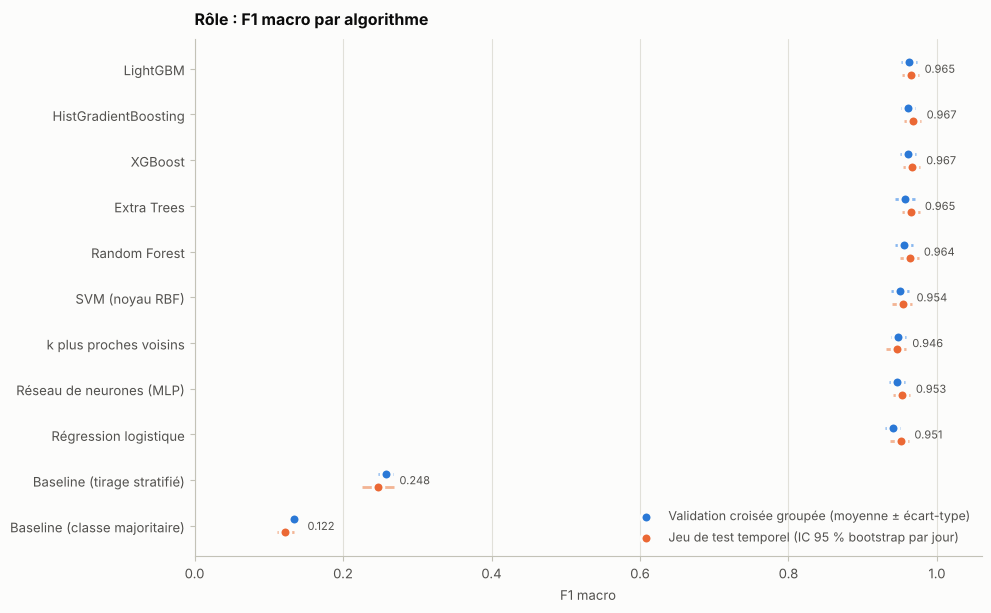

**Origine (Russie ou Ukraine)** (tri par validation croisée)

,modele,f1_cv,f1_cv_ecart_type,f1_apprentissage,f1_test,ic_bas,ic_haut,exactitude_equilibree_test,log_loss_test,auc_test,duree_s
0,Extra Trees,0.991,0.002,1.000,0.993,0.988,0.997,0.993,0.031,1.000,32.788
1,LightGBM,0.991,0.002,1.000,0.991,0.985,0.996,0.991,0.027,1.000,15.159
2,Random Forest,0.990,0.002,1.000,0.991,0.985,0.996,0.991,0.039,1.000,125.117
3,XGBoost,0.990,0.002,1.000,0.986,0.979,0.993,0.990,0.033,0.999,11.348
4,HistGradientBoosting,0.990,0.003,1.000,0.992,0.986,0.996,0.993,0.028,1.000,108.929
5,SVM (noyau RBF),0.989,0.003,0.994,0.992,0.986,0.997,0.994,0.028,0.999,16.651
6,Réseau de neurones (MLP),0.988,0.003,0.997,0.985,0.978,0.991,0.986,0.041,0.999,14.879
7,k plus proches voisins,0.980,0.006,0.985,0.986,0.979,0.992,0.989,0.060,0.999,4.541
8,Régression logistique,0.976,0.007,0.980,0.972,0.960,0.982,0.980,0.065,0.997,1.803
9,Baseline (tirage stratifié),0.496,0.006,0.496,0.485,0.462,0.506,0.487,16.280,0.487,0.239


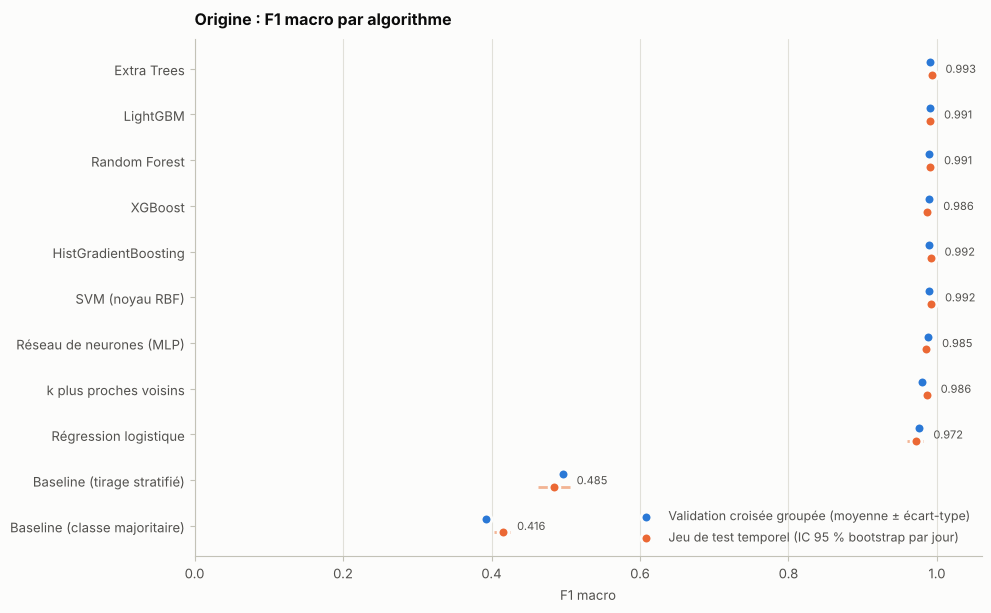

**Modèle exact (12 classes)** (tri par validation croisée)

,modele,f1_cv,f1_cv_ecart_type,f1_apprentissage,f1_test,ic_bas,ic_haut,exactitude_equilibree_test,log_loss_test,auc_test,duree_s
0,XGBoost,0.775,0.018,0.991,0.741,0.664,0.787,0.753,0.351,0.989,127.739
1,LightGBM,0.773,0.009,1.000,0.739,0.663,0.777,0.748,0.352,0.990,148.872
2,HistGradientBoosting,0.770,0.013,1.000,0.721,0.650,0.761,0.727,0.560,0.988,290.681
3,Random Forest,0.770,0.014,0.887,0.726,0.661,0.768,0.746,0.418,0.989,167.150
4,Extra Trees,0.759,0.010,0.985,0.739,0.668,0.787,0.751,0.402,0.989,50.226
5,Régression logistique,0.738,0.011,0.810,0.710,0.651,0.749,0.725,0.421,0.987,31.182
6,SVM (noyau RBF),0.737,0.006,0.840,0.713,0.647,0.755,0.723,0.380,0.987,38.751
7,Réseau de neurones (MLP),0.724,0.008,0.806,0.686,0.615,0.733,0.698,0.405,0.986,20.272
8,k plus proches voisins,0.698,0.020,1.000,0.656,0.597,0.693,0.665,0.607,0.978,4.194
9,Baseline (tirage stratifié),0.081,0.005,0.087,0.085,0.074,0.096,0.087,30.875,0.502,0.270


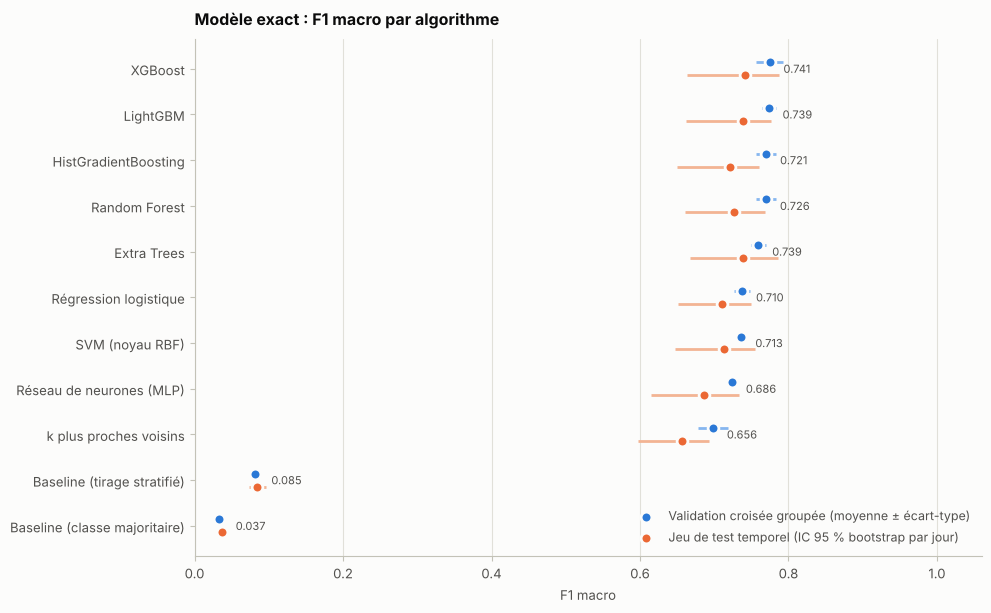

In [5]:
colonnes = ["modele", "f1_cv", "f1_cv_ecart_type", "f1_apprentissage", "f1_test", "ic_bas", "ic_haut",
            "exactitude_equilibree_test", "log_loss_test", "auc_test", "duree_s"]
for cible in ml.CIBLES:
    display(Markdown(f"**{ml.CIBLES[cible]}** (tri par validation croisée)"))
    display(resultats[cible][colonnes].sort_values("f1_cv", ascending=False).reset_index(drop=True))
    fig = viz.fig_comparaison_modeles(resultats[cible], f"{LIB[cible]} : F1 macro par algorithme")
    viz.sauver(fig, f"11_comparaison_modeles_{cible}_v2")
    plt.show()

In [6]:
display(Markdown("**Hyperparamètres retenus (rôle)**"))
display(resultats["role"][["modele", "hyperparametres"]])

**Hyperparamètres retenus (rôle)**

,modele,hyperparametres
0,Baseline (classe majoritaire),
1,Baseline (tirage stratifié),
2,Régression logistique,C=76.4
3,k plus proches voisins,"n_neighbors=20, p=1, weights=distance"
4,SVM (noyau RBF),"C=2.42, gamma=0.0187"
5,Random Forest,"min_samples_leaf=1, max_features=sqrt, max_dep..."
6,Extra Trees,"min_samples_leaf=1, max_features=0.5, max_dept..."
7,HistGradientBoosting,"l2_regularization=0.539, learning_rate=0.0818,..."
8,XGBoost,"colsample_bytree=0.5, learning_rate=0.0711, ma..."
9,LightGBM,"colsample_bytree=0.5, learning_rate=0.021, min..."


## 4. Modèles retenus : détail par classe

Rapport par classe sur le jeu de test, matrices de confusion normalisées par ligne (chaque ligne = classe réelle) et comparaison appariée avec d'autres algorithmes (bootstrap des jours de test : la différence est significative si l'intervalle exclut zéro).

In [7]:
predictions = test[["piste_id", "jour", "modele", "origine", "role", "duree_min", "nb_fragments"]].copy()
probas = {}
for cible in ml.CIBLES:
    enc, m = encodeurs[cible], modeles[cible][choisis[cible]]
    probas[cible] = m.predict_proba(test[VARIABLES])
    pred = probas[cible].argmax(axis=1)
    predictions[f"{cible}_predit"] = enc.inverse_transform(pred)
    predictions[f"{cible}_confiance"] = probas[cible].max(axis=1)
    display(Markdown(f"**{ml.CIBLES[cible]} : {choisis[cible]}**"))
    rapport = classification_report(enc.transform(test[cible]), pred, target_names=enc.classes_, output_dict=True)
    display(pd.DataFrame(rapport).T)

**Rôle (frappe, leurre, munition rôdeuse, reconnaissance) : LightGBM**

,precision,recall,f1-score,support
Frappe longue portée,0.967,0.975,0.971,604.000
Leurre,0.955,0.934,0.944,391.000
Munition rôdeuse,0.943,0.985,0.964,268.000
Reconnaissance,0.986,0.973,0.980,599.000
accuracy,0.967,0.967,0.967,0.967
macro avg,0.963,0.967,0.965,1 862.000
weighted avg,0.967,0.967,0.967,1 862.000


**Origine (Russie ou Ukraine) : Extra Trees**

,precision,recall,f1-score,support
Russie,0.995,0.996,0.996,1 325.000
Ukraine,0.991,0.989,0.990,537.000
accuracy,0.994,0.994,0.994,0.994
macro avg,0.993,0.993,0.993,1 862.000
weighted avg,0.994,0.994,0.994,1 862.000


**Modèle exact (12 classes) : XGBoost**

,precision,recall,f1-score,support
A1-SM Furia,0.720,0.540,0.618,124.000
An-196 Liutyi,0.367,0.579,0.449,19.000
Gerbera,0.956,0.939,0.947,391.000
Lancet-3,0.981,0.987,0.984,154.000
Leleka-100,0.595,0.567,0.581,127.000
Orlan-10,0.803,0.753,0.777,146.000
Shahed-136 (Geran-2),0.966,0.964,0.965,527.000
Supercam S350,0.698,0.757,0.726,107.000
UJ-22 Airborne,0.750,0.568,0.646,37.000
UJ-26 Bober (Babor v1),0.545,0.571,0.558,21.000


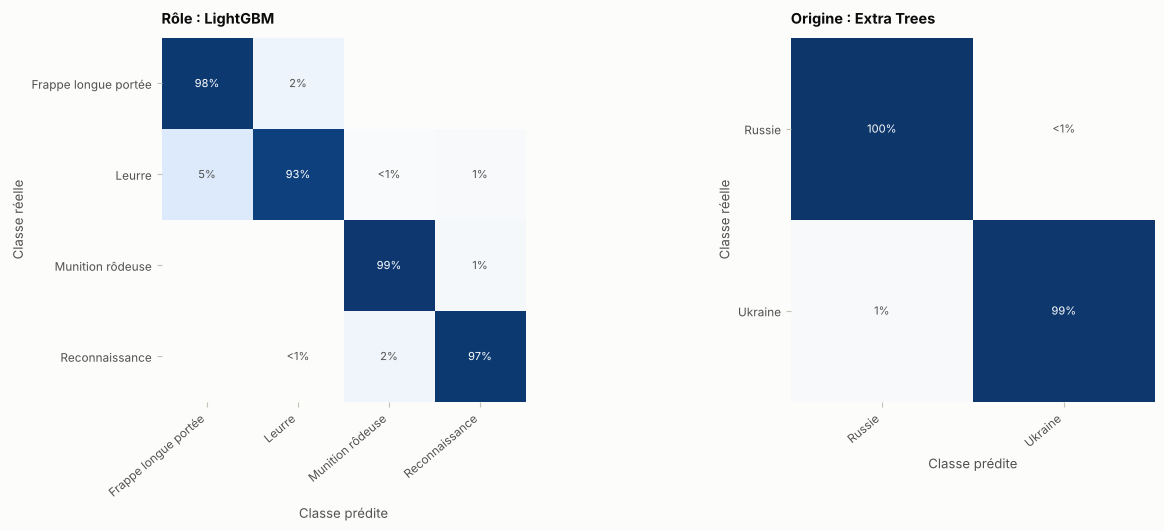

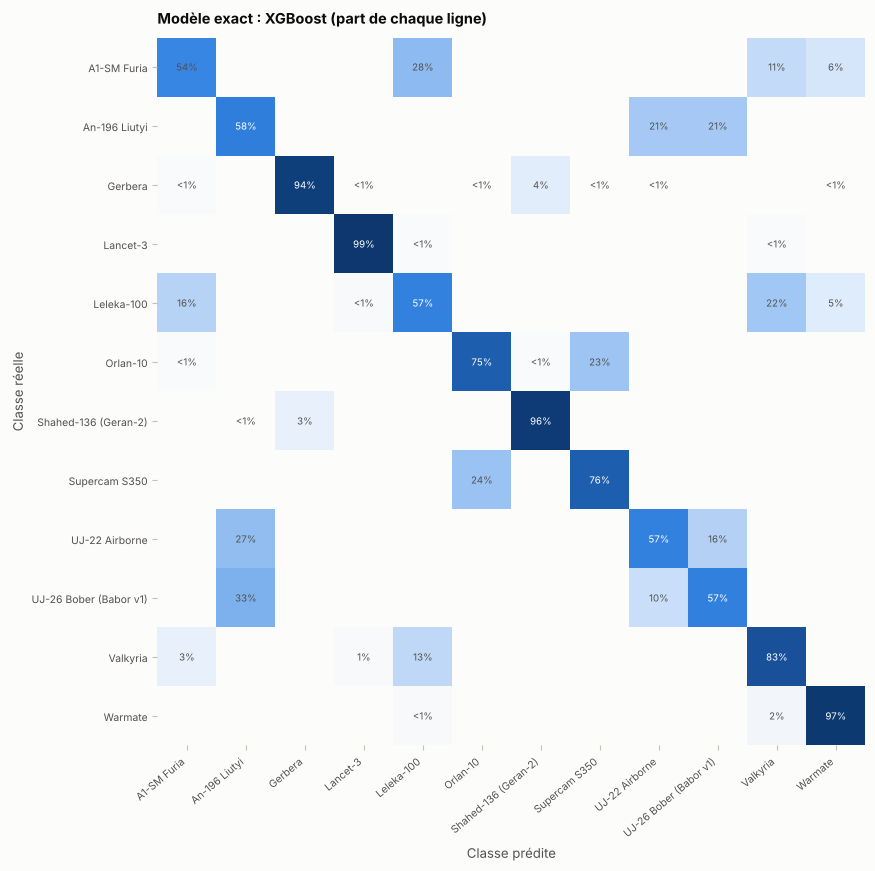

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), gridspec_kw=dict(width_ratios=[1.35, 1]))
for ax, cible in zip(axes, ["role", "origine"]):
    enc = encodeurs[cible]
    cm = confusion_matrix(test[cible], predictions[f"{cible}_predit"], labels=enc.classes_)
    viz.fig_confusion(cm, enc.classes_, f"{LIB[cible]} : {choisis[cible]}", ax=ax, taille=8.5)
fig.tight_layout()
viz.sauver(fig, "12_confusion_role_origine_v2")
plt.show()
fig, ax = plt.subplots(figsize=(10.5, 8.8))
enc = encodeurs["modele"]
cm = confusion_matrix(test.modele, predictions.modele_predit, labels=enc.classes_)
viz.fig_confusion(cm, enc.classes_, f"Modèle exact : {choisis['modele']} (part de chaque ligne)", ax=ax, taille=7.5)
fig.tight_layout()
viz.sauver(fig, "13_confusion_modele_v2")
plt.show()

In [9]:
lignes = []
for cible in ml.CIBLES:
    enc = encodeurs[cible]
    y, g = enc.transform(test[cible]), test.jour.to_numpy()
    p_retenu = modeles[cible][choisis[cible]].predict(test[VARIABLES])
    for autre in ["Random Forest", "XGBoost", "Régression logistique"]:
        if autre != choisis[cible]:
            p_autre = modeles[cible][autre].predict(test[VARIABLES])
            lignes.append(dict(cible=cible, modele_retenu=choisis[cible], compare_a=autre,
                               **ml.difference_appariee(y, p_retenu, p_autre, g)))
comparaisons = pd.DataFrame(lignes)
comparaisons["significatif"] = (comparaisons.ic_bas > 0) | (comparaisons.ic_haut < 0)
display(comparaisons)

,cible,modele_retenu,compare_a,diff,ic_bas,ic_haut,p_inferieur_ou_egal,significatif
0,role,LightGBM,Random Forest,0.001,-0.004,0.006,0.322,False
1,role,LightGBM,XGBoost,-0.002,-0.006,0.002,0.837,False
2,role,LightGBM,Régression logistique,0.014,0.005,0.024,0.001,True
3,origine,Extra Trees,Random Forest,0.002,-0.001,0.005,0.125,False
4,origine,Extra Trees,XGBoost,0.006,0.002,0.012,0.005,True
5,origine,Extra Trees,Régression logistique,0.021,0.012,0.032,0.000,True
6,modele,XGBoost,Random Forest,0.015,-0.016,0.040,0.185,False
7,modele,XGBoost,Régression logistique,0.032,-0.018,0.068,0.104,False


## 5. Diagnostics de sur-apprentissage (rôle)

* **Courbes d'apprentissage** : score d'apprentissage et de validation croisée groupée selon la taille de l'échantillon. Un écart qui se réduit quand les données augmentent indique que le modèle généralise ; un plateau bas indiquerait un sous-apprentissage.
* **Courbes de validation** : effet de la complexité (taille minimale des feuilles d'une forêt, nombre d'arbres d'un boosting). Le score d'apprentissage monte toujours avec la complexité ; seul le score de validation guide le réglage.

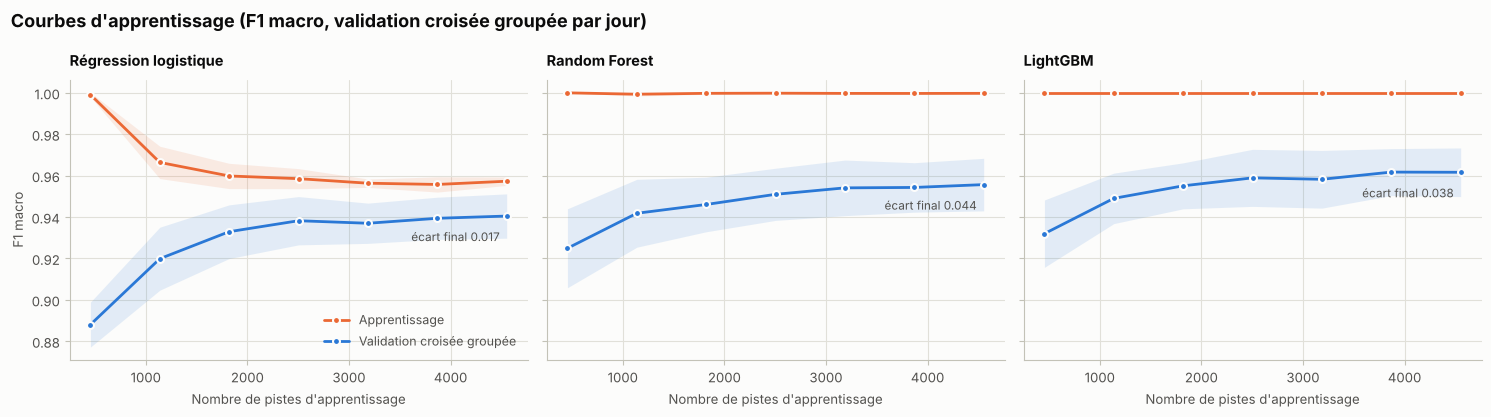

,f1_apprentissage,f1_validation,ecart
Régression logistique,0.957,0.940,0.017
Random Forest,1.000,0.956,0.044
LightGBM,1.000,0.962,0.038


In [10]:
cible = "role"
enc, nom = encodeurs[cible], choisis[cible]
Xtr, ytr, gtr = train[VARIABLES], enc.transform(train[cible]), train.jour.to_numpy()
courbes = {n: ml.courbes_apprentissage(modeles[cible][n], Xtr, ytr, gtr, nom=n)
           for n in dict.fromkeys(["Régression logistique", "Random Forest", nom])}
fig = viz.fig_courbes_apprentissage(courbes)
viz.sauver(fig, "14_courbes_apprentissage_v2")
plt.show()
ecarts = pd.DataFrame({n: dict(f1_apprentissage=c[1].mean(axis=1)[-1], f1_validation=c[2].mean(axis=1)[-1])
                       for n, c in courbes.items()}).T
ecarts["ecart"] = ecarts.f1_apprentissage - ecarts.f1_validation
display(ecarts)

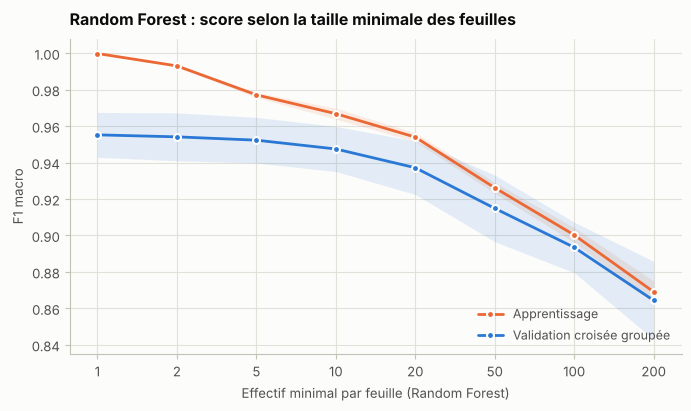

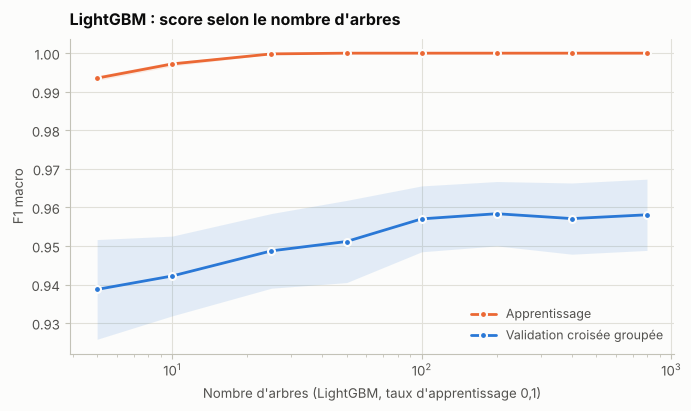

Random Forest : meilleure validation 0.955 pour min_samples_leaf = 1
LightGBM : meilleure validation 0.958 pour 200 arbres ; à 800 arbres : apprentissage 1.000, validation 0.958


In [11]:
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier

foret = ml._pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=1,
                                        random_state=config.GRAINE))
feuilles = [1, 2, 5, 10, 20, 50, 100, 200]
s_tr, s_va = ml.courbe_validation(foret, Xtr, ytr, gtr, "clf__min_samples_leaf", feuilles)
fig = viz.fig_courbe_validation(feuilles, s_tr, s_va, "Effectif minimal par feuille (Random Forest)",
                                "Random Forest : score selon la taille minimale des feuilles")
viz.sauver(fig, "15_courbe_validation_foret_v2")
plt.show()
boosting = ml._pipe(LGBMClassifier(learning_rate=0.1, num_leaves=63, min_child_samples=5, class_weight="balanced",
                                   n_jobs=1, random_state=config.GRAINE, verbose=-1))
arbres = [5, 10, 25, 50, 100, 200, 400, 800]
s_tr2, s_va2 = ml.courbe_validation(boosting, Xtr, ytr, gtr, "clf__n_estimators", arbres)
fig = viz.fig_courbe_validation(arbres, s_tr2, s_va2, "Nombre d'arbres (LightGBM, taux d'apprentissage 0,1)",
                                "LightGBM : score selon le nombre d'arbres", log=True)
viz.sauver(fig, "16_courbe_validation_boosting_v2")
plt.show()
print(f"Random Forest : meilleure validation {s_va.mean(axis=1).max():.3f} pour min_samples_leaf = "
      f"{feuilles[int(s_va.mean(axis=1).argmax())]}")
print(f"LightGBM : meilleure validation {s_va2.mean(axis=1).max():.3f} pour {arbres[int(s_va2.mean(axis=1).argmax())]} arbres ; "
      f"à 800 arbres : apprentissage {s_tr2.mean(axis=1)[-1]:.3f}, validation {s_va2.mean(axis=1)[-1]:.3f}")

## 6. Test de permutation des étiquettes

Les étiquettes de l'apprentissage sont permutées au hasard (à l'intérieur de chaque jour) puis le modèle est réévalué en validation croisée groupée. Si le modèle apprenait du bruit ou exploitait une fuite, il obtiendrait un score comparable sur étiquettes permutées. La p-valeur est la part des permutations qui font au moins aussi bien que les vraies étiquettes.

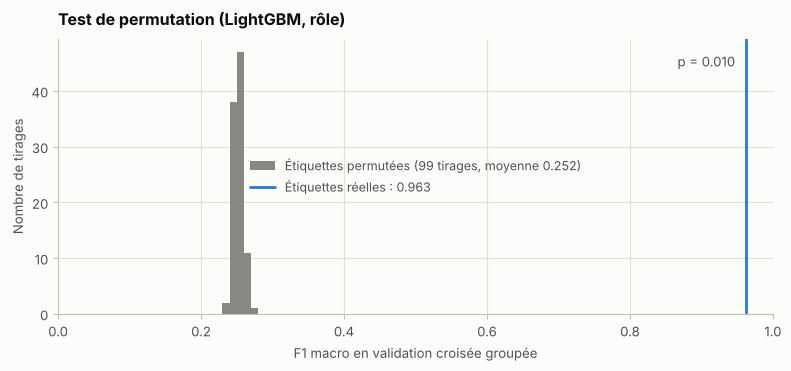

F1 macro avec les vraies étiquettes : 0.963
Étiquettes permutées : moyenne 0.252, maximum 0.270 sur 99 tirages
p-valeur = 0.010 (plus petite valeur atteignable : 0.010)


In [12]:
n_perm = 19 if RAPIDE else 99
score, perms, p_valeur = ml.test_permutation(modeles[cible][nom], Xtr, ytr, gtr, n_permutations=n_perm)
fig = viz.fig_permutation(score, perms, p_valeur, f"Test de permutation ({nom}, rôle)")
viz.sauver(fig, "17_test_permutation_v2")
plt.show()
print(f"F1 macro avec les vraies étiquettes : {score:.3f}")
print(f"Étiquettes permutées : moyenne {perms.mean():.3f}, maximum {perms.max():.3f} sur {n_perm} tirages")
print(f"p-valeur = {p_valeur:.3f} (plus petite valeur atteignable : {1 / (n_perm + 1):.3f})")

## 7. Calibration des probabilités (rôle)

Un modèle bien calibré qui annonce 80 % de confiance a raison environ 8 fois sur 10. L'erreur de calibration attendue (ECE) résume l'écart ; le score de Brier mesure à la fois calibration et précision (0 = parfait).

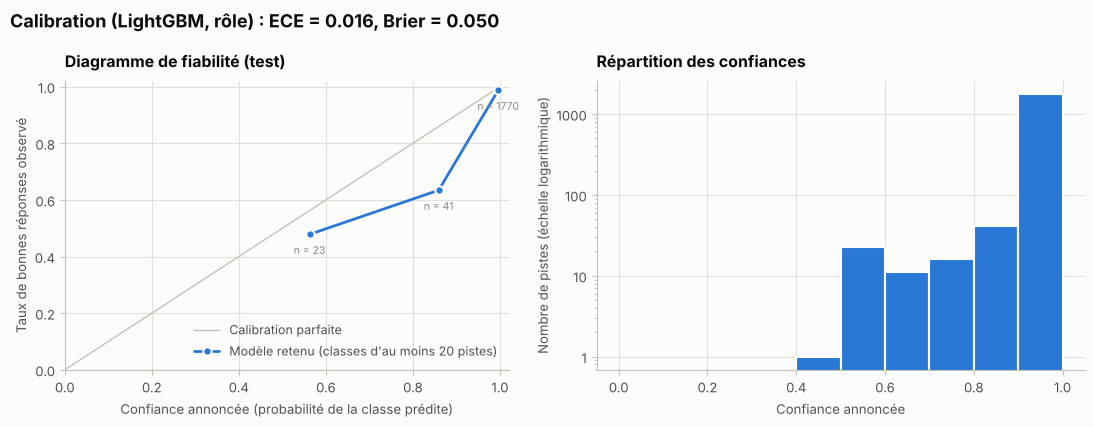

In [13]:
y_role = enc.transform(test.role)
proba_role = probas["role"]
ece = ml.erreur_calibration(y_role, proba_role)
brier = float(np.mean(np.sum((proba_role - np.eye(len(enc.classes_))[y_role]) ** 2, axis=1)))
fig = viz.fig_calibration(y_role, proba_role, f"Calibration ({nom}, rôle) : ECE = {ece:.3f}, Brier = {brier:.3f}")
viz.sauver(fig, "18_calibration_v2")
plt.show()

## 8. Interprétation

* **Importance par permutation sur le test** : baisse du F1 macro quand une variable est mélangée. Mesurée sur des données jamais vues, elle reflète ce qui sert réellement à généraliser.
* **Valeurs SHAP** (TreeSHAP natif de XGBoost) : contribution moyenne de chaque variable à la décision, classe par classe.

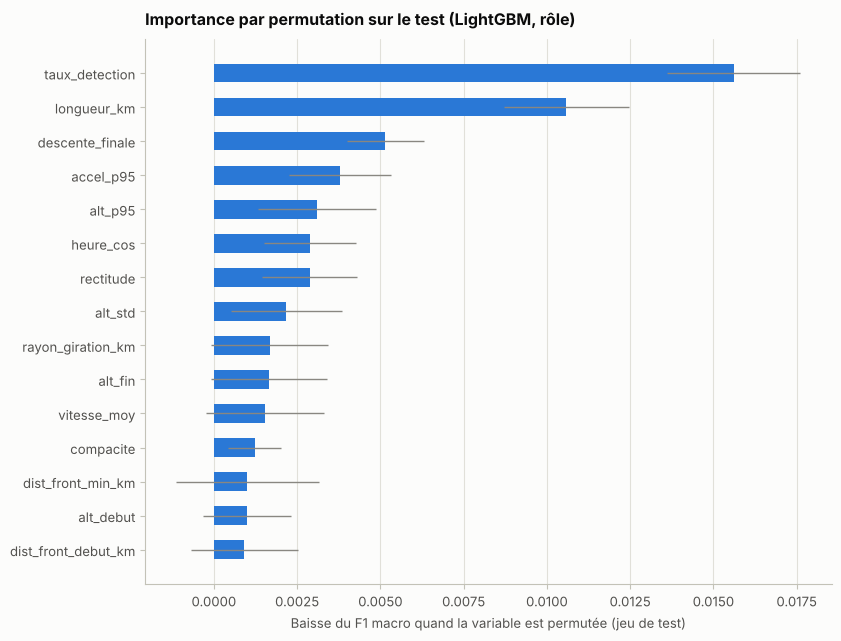

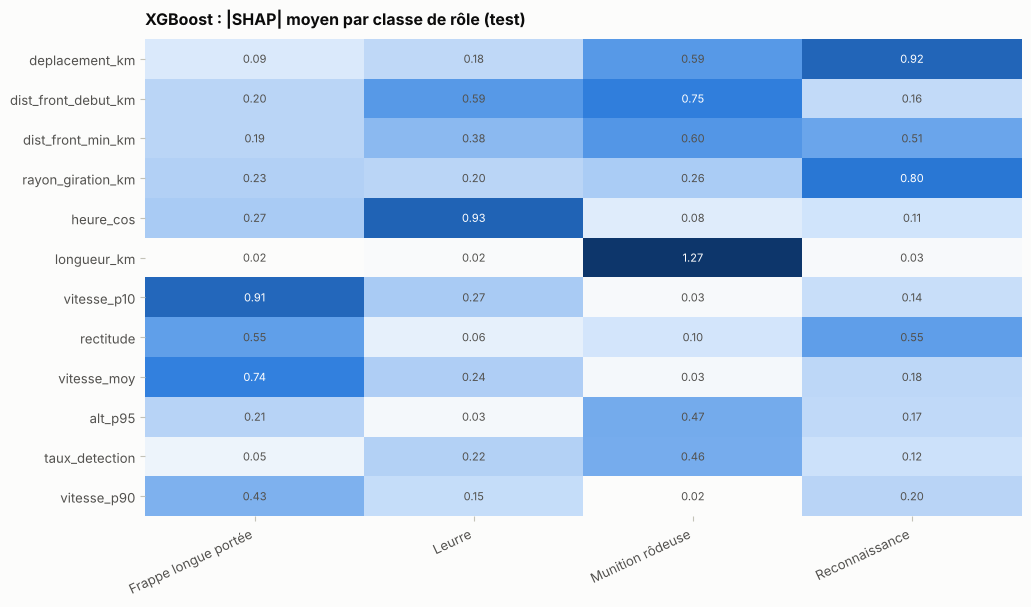

**Origine (Extra Trees) : dix variables les plus utiles**

,variable,importance,ecart_type
0,vitesse_vers_ua_kmh,0.125,0.008
1,dist_front_debut_km,0.118,0.007
2,taux_detection,0.020,0.002
3,vitesse_p10,0.001,0.001
4,cap_net_cos,0.001,0.001
5,longueur_km,0.000,0.001
6,alt_fin,0.000,0.000
7,n_plots,0.000,0.001
8,vz_p05,0.000,0.000
9,vitesse_p95,0.000,0.000


In [14]:
importance = ml.importance_par_permutation(modeles["role"][nom], test[VARIABLES], y_role)
fig = viz.fig_importance(importance, f"Importance par permutation sur le test ({nom}, rôle)")
viz.sauver(fig, "19_importance_permutation_v2")
plt.show()
shap_moy, _ = ml.shap_xgboost(modeles["role"]["XGBoost"], test[VARIABLES])
fig = viz.fig_shap(shap_moy, list(enc.classes_), VARIABLES, titre="XGBoost : |SHAP| moyen par classe de rôle (test)")
viz.sauver(fig, "20_shap_xgboost_v2")
plt.show()
y_orig = encodeurs["origine"].transform(test.origine)
importance_origine = ml.importance_par_permutation(modeles["origine"][choisis["origine"]], test[VARIABLES], y_orig)
display(Markdown(f"**Origine ({choisis['origine']}) : dix variables les plus utiles**"))
display(importance_origine.head(10))

## 9. Ablation par famille de variables

Le modèle retenu est réentraîné avec des sous-ensembles de variables. Cette expérience montre si la performance repose sur la physique du vol (cinématique, altitude) ou sur des indices de contexte (géographie, heure), plus fragiles hors du simulateur.

**Rôle**

,jeu,n_variables,f1_cv,f1_cv_ecart_type,f1_test
0,Cinématique seule,17,0.912,0.022,0.928
1,Altitude seule,10,0.744,0.018,0.746
2,Cinématique + altitude,27,0.942,0.008,0.957
3,+ observation,30,0.948,0.009,0.962
4,+ géographie,40,0.961,0.010,0.964
5,Toutes (+ heure),42,0.963,0.011,0.965


**Origine**

,jeu,n_variables,f1_cv,f1_cv_ecart_type,f1_test
0,Cinématique seule,17,0.817,0.031,0.862
1,Altitude seule,10,0.809,0.005,0.817
2,Cinématique + altitude,27,0.885,0.012,0.899
3,+ observation,30,0.895,0.013,0.911
4,+ géographie,40,0.990,0.002,0.993
5,Toutes (+ heure),42,0.991,0.002,0.993


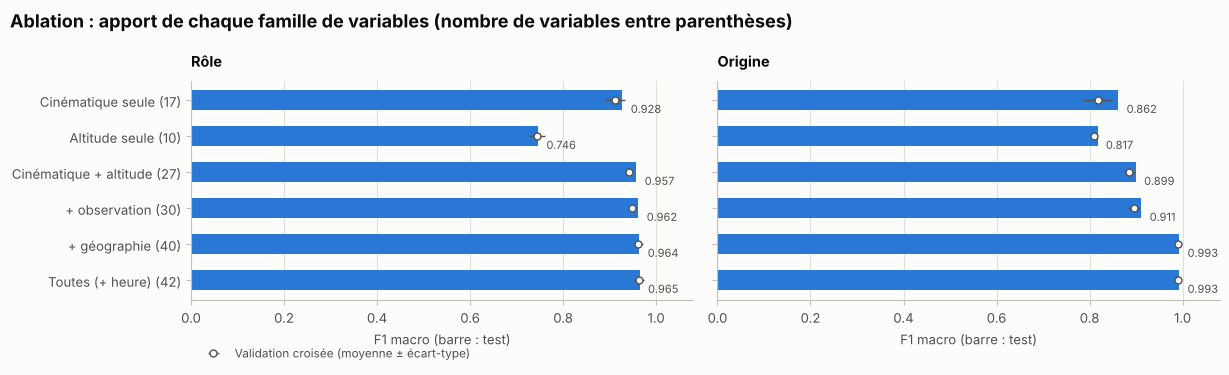

In [15]:
ablations = {c: xp.ablation(modeles[c][choisis[c]], train, test, c, encodeurs[c], nom=choisis[c])
             for c in ["role", "origine"]}
for c, t in ablations.items():
    display(Markdown(f"**{LIB[c]}**"))
    display(t)
fig = viz.fig_ablation(ablations, LIB)
viz.sauver(fig, "21_ablation_familles_v2")
plt.show()

## 10. Classification précoce

En situation réelle, il faut décider pendant le vol. Les variables sont recalculées sur les seules premières minutes de chaque piste (apprentissage et test), puis le modèle retenu est réentraîné pour chaque horizon.

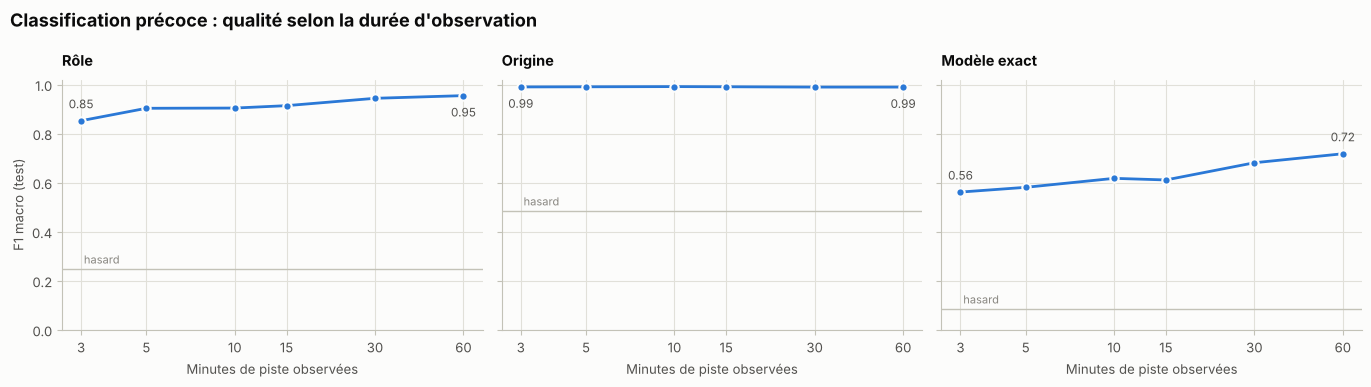

cible,modele,origine,role
horizon_min,,,
3,0.562,0.990,0.852
5,0.581,0.991,0.903
10,0.617,0.992,0.904
15,0.611,0.991,0.914
30,0.681,0.990,0.944
60,0.718,0.990,0.955


In [16]:
plots = donnees.charger_plots()
theatre = Theatre()
retenus = {c: modeles[c][choisis[c]] for c in ml.CIBLES}
horizons = (3, 10, 30) if RAPIDE else (3, 5, 10, 15, 30, 60)
precoce = xp.classification_precoce(retenus, pistes, plots, theatre, list(ml.CIBLES), encodeurs,
                                    horizons=horizons, noms=choisis)
reference = {c: float(resultats[c].set_index("modele").loc["Baseline (tirage stratifié)", "f1_test"])
             for c in ml.CIBLES}
fig = viz.fig_courbes_par_cible(precoce, "horizon_min", "f1_test", "Minutes de piste observées",
                                "Classification précoce : qualité selon la durée d'observation", LIB,
                                xlog=True, reference=reference)
viz.sauver(fig, "22_classification_precoce_v2")
plt.show()
display(precoce.pivot(index="horizon_min", columns="cible", values="f1_test"))

## 11. Robustesse à un radar dégradé

Les vols des 30 jours de test sont réobservés avec un nouveau tirage du bruit, à niveau nominal puis multiplié jusqu'à quatre fois. Les modèles, entraînés au bruit nominal, ne sont pas modifiés.

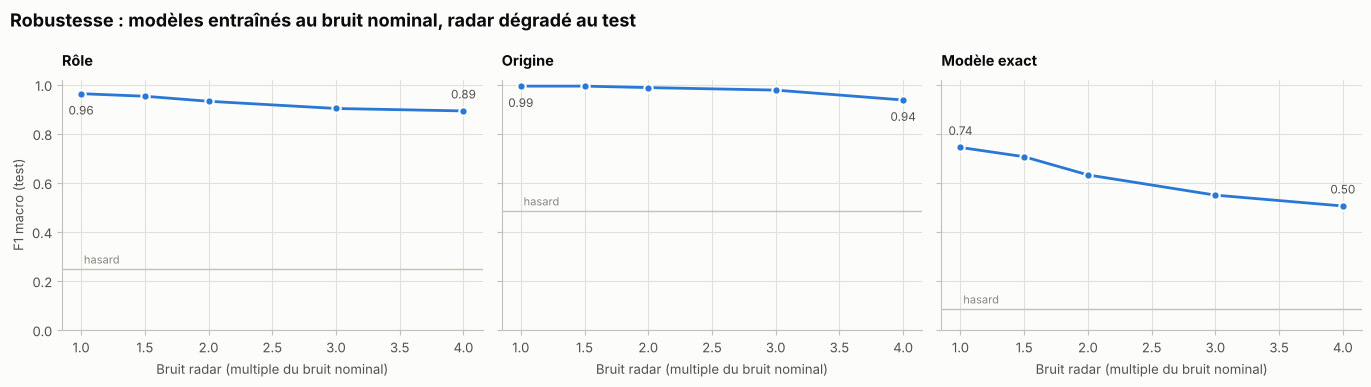

cible,modele,origine,role
facteur_bruit,,,
1.000,0.743,0.993,0.963
1.500,0.706,0.993,0.952
2.000,0.632,0.987,0.932
3.000,0.549,0.977,0.902
4.000,0.505,0.937,0.892


In [17]:
facteurs = (1.0, 2.0, 3.0) if RAPIDE else (1.0, 1.5, 2.0, 3.0, 4.0)
bruit = xp.robustesse_bruit(retenus, encodeurs, theatre, facteurs=facteurs)
fig = viz.fig_courbes_par_cible(bruit, "facteur_bruit", "f1_test", "Bruit radar (multiple du bruit nominal)",
                                "Robustesse : modèles entraînés au bruit nominal, radar dégradé au test", LIB,
                                reference=reference)
viz.sauver(fig, "23_robustesse_bruit_v2")
plt.show()
display(bruit.pivot(index="facteur_bruit", columns="cible", values="f1_test"))

## 12. Généralisation à un secteur géographique jamais vu

Les pistes sont rangées en trois secteurs selon leur premier plot (nord au-delà de 50° N, sud en deçà de 47,8° N, est entre les deux). Pour chaque secteur, un modèle qui l'a vu à l'apprentissage est comparé à un modèle qui ne l'a jamais vu. Seules les variables physiques sont utilisées (cinématique, altitude, observation) : l'objectif est de vérifier que la signature de vol se transpose d'une région à l'autre.

In [18]:
lat_debut = pistes.set_index("piste_id").lat_debut
sect_tr = xp.secteur(train.piste_id.map(lat_debut))
sect_te = xp.secteur(test.piste_id.map(lat_debut))
display(pd.crosstab(pd.concat([sect_tr, sect_te], ignore_index=True).rename("secteur"),
                    pd.concat([train.role, test.role], ignore_index=True)))
geo = pd.concat([xp.generalisation_geographique(modeles["role"][choisis["role"]], train, test, "role",
                                                 encodeurs["role"], sect_tr, sect_te, exclu=s, nom=choisis["role"])
                 for s in ["Nord", "Est", "Sud"]], ignore_index=True)
display(geo)

role,Frappe longue portée,Leurre,Munition rôdeuse,Reconnaissance
secteur,,,,
Est,681,302,333,882
Nord,1141,648,240,725
Sud,856,435,467,848


,cas,secteur_test,n_apprentissage,n_test,f1_test
0,Secteur vu à l'apprentissage,Nord,5696,656,0.958
1,Secteur jamais vu,Nord,3598,656,0.954
2,Secteur vu à l'apprentissage,Est,5696,587,0.959
3,Secteur jamais vu,Est,4085,587,0.950
4,Secteur vu à l'apprentissage,Sud,5696,619,0.965
5,Secteur jamais vu,Sud,3709,619,0.965


## 13. Comparaison avec la v1 et effet d'un découpage naïf

* **Variables de la v1** (distance de la première détection à la frontière, direction, changement de direction, vitesse et altitude des cinq premiers points) recalculées sur les pistes radar de la v2, avec la forêt aléatoire de la v1 (100 arbres). Dans la v1, l'altitude était tirée selon le type de drone (bandes disjointes entre drones suicide et de reconnaissance) et tous les drones russes entraient dans la zone par sa bordure : les deux tâches étaient séparables par construction, d'où les 100 % d'exactitude. On mesure ici ce que valent ces cinq variables sur des pistes réalistes.
* **Découpage naïf** : validation croisée aléatoire (pistes d'un même raid des deux côtés) comparée à la validation croisée groupée par jour, sur les mêmes données d'apprentissage.

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

v1 = xp.variables_v1(plots, theatre)
d1 = variables[["piste_id", "jour", "role", "origine", "modele"]].merge(v1, on="piste_id")
tr1, te1 = ml.decouper(d1)
lignes = []
for c in ml.CIBLES:
    enc_c = encodeurs[c]
    foret_v1 = RandomForestClassifier(n_estimators=100, random_state=config.GRAINE, n_jobs=4)
    foret_v1.fit(tr1[xp.VARIABLES_V1], enc_c.transform(tr1[c]))
    f1_v1 = f1_score(enc_c.transform(te1[c]), foret_v1.predict(te1[xp.VARIABLES_V1]), average="macro")
    lignes.append(dict(cible=c, f1_test_variables_v1=f1_v1,
                       f1_test_variables_v2=float(resultats[c].set_index("modele").loc[choisis[c], "f1_test"])))
v1_v2 = pd.DataFrame(lignes)
display(v1_v2)

,cible,f1_test_variables_v1,f1_test_variables_v2
0,role,0.657,0.965
1,origine,0.796,0.993
2,modele,0.347,0.741


In [20]:
lignes = []
foret = ml._pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=4,
                                        random_state=config.GRAINE))
for c in ml.CIBLES:
    y = encodeurs[c].transform(train[c])
    naif = cross_val_score(foret, train[VARIABLES], y, scoring="f1_macro",
                           cv=StratifiedKFold(5, shuffle=True, random_state=config.GRAINE))
    groupe = cross_val_score(foret, train[VARIABLES], y, groups=train.jour, cv=ml.cv_groupee(), scoring="f1_macro")
    lignes.append(dict(cible=c, cv_aleatoire=naif.mean(), cv_groupee_par_jour=groupe.mean(),
                       optimisme=naif.mean() - groupe.mean()))
decoupage = pd.DataFrame(lignes)
display(decoupage)

,cible,cv_aleatoire,cv_groupee_par_jour,optimisme
0,role,0.957,0.955,0.002
1,origine,0.991,0.990,0.001
2,modele,0.802,0.769,0.033


## 14. Analyse des erreurs (rôle)

Les erreurs se concentrent-elles sur les pistes courtes, fragmentées ou sur certaines paires de classes ? La carte situe les pistes mal classées du jeu de test.

In [21]:
classes_duree = pd.cut(test.duree_min, [0, 10, 30, 60, 120, np.inf],
                       labels=["moins de 10 min", "10 à 30 min", "30 à 60 min", "1 à 2 h", "plus de 2 h"])
par_duree = (predictions.assign(classe=classes_duree)
             .groupby("classe", observed=True)
             .apply(lambda g: pd.Series(dict(pistes=len(g), exactitude=(g.role == g.role_predit).mean(),
                                             f1_macro=f1_score(g.role, g.role_predit, average="macro")))))
display(par_duree)
fragmente = predictions.nb_fragments > 1
print(f"Exactitude (rôle) : vols observés en une seule piste {(predictions.role == predictions.role_predit)[~fragmente].mean():.3f}, "
      f"vols fragmentés {(predictions.role == predictions.role_predit)[fragmente].mean():.3f}")
conf = pd.crosstab(test.modele, predictions.modele_predit)
paires = [(r, c_, int(conf.loc[r, c_])) for r in conf.index for c_ in conf.columns if r != c_ and conf.loc[r, c_] > 0]
display(Markdown("**Confusions les plus fréquentes entre modèles (test)**"))
display(pd.DataFrame(sorted(paires, key=lambda t: -t[2])[:10], columns=["modele_reel", "modele_predit", "pistes"]))

,pistes,exactitude,f1_macro
classe,,,
moins de 10 min,37.000,0.892,0.863
10 à 30 min,368.000,0.946,0.934
30 à 60 min,233.000,0.957,0.942
1 à 2 h,569.000,0.975,0.964
plus de 2 h,655.000,0.980,0.980


Exactitude (rôle) : vols observés en une seule piste 0.972, vols fragmentés 0.929


**Confusions les plus fréquentes entre modèles (test)**

,modele_reel,modele_predit,pistes
0,A1-SM Furia,Leleka-100,35
1,Orlan-10,Supercam S350,34
2,Leleka-100,Valkyria,28
3,Supercam S350,Orlan-10,26
4,Leleka-100,A1-SM Furia,20
5,Gerbera,Shahed-136 (Geran-2),17
6,Shahed-136 (Geran-2),Gerbera,17
7,A1-SM Furia,Valkyria,14
8,Valkyria,Leleka-100,12
9,UJ-22 Airborne,An-196 Liutyi,10


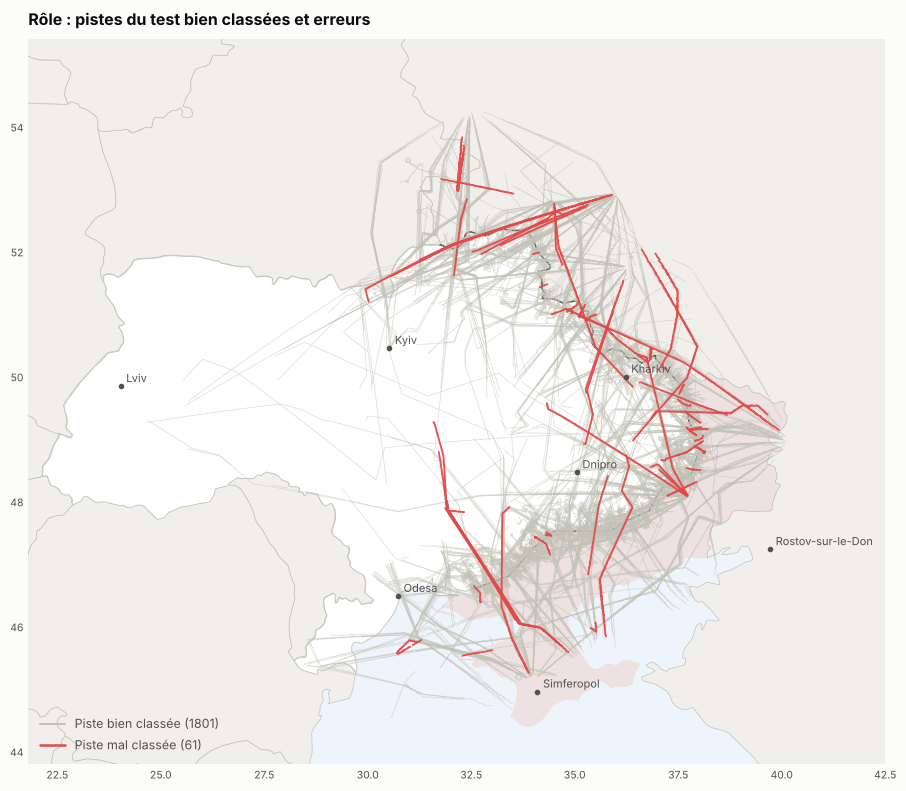

In [22]:
plots_test = plots[plots.piste_id.isin(set(test.piste_id))]
correct = pd.Series((predictions.role_predit == predictions.role).to_numpy(), index=predictions.piste_id)
fig = viz.fig_carte_erreurs(theatre, plots_test, correct, "Rôle : pistes du test bien classées et erreurs")
viz.sauver(fig, "24_carte_erreurs_role_v2")
plt.show()

## 15. Sauvegarde des résultats

In [23]:
predictions.to_csv(config.RAPPORTS / "predictions_test_v2.csv", index=False)

def ligne_resultat(cible):
    r = resultats[cible].set_index("modele")
    retenu = r.loc[choisis[cible]]
    return dict(
        modele_retenu=choisis[cible], f1_cv=retenu.f1_cv, f1_cv_ecart_type=retenu.f1_cv_ecart_type,
        f1_apprentissage=retenu.f1_apprentissage, f1_test=retenu.f1_test,
        f1_test_ic95=[retenu.ic_bas, retenu.ic_haut], exactitude_test=retenu.exactitude_test,
        exactitude_equilibree_test=retenu.exactitude_equilibree_test, auc_test=retenu.auc_test,
        f1_test_baseline_majoritaire=r.loc["Baseline (classe majoritaire)", "f1_test"],
        f1_test_baseline_stratifiee=r.loc["Baseline (tirage stratifié)", "f1_test"],
        f1_test_par_modele=r.f1_test.to_dict(), f1_cv_par_modele=r.f1_cv.to_dict())

metriques = dict(
    jeu=dict(pistes=len(variables), apprentissage=len(train), test=len(test), variables=len(VARIABLES)),
    cibles={c: ligne_resultat(c) for c in ml.CIBLES},
    permutation=dict(f1_reel=score, f1_permute_moyen=float(perms.mean()), f1_permute_max=float(perms.max()),
                     p_valeur=p_valeur, n_permutations=n_perm),
    calibration=dict(ece=ece, brier=brier),
    ecart_apprentissage_validation=ecarts.ecart.to_dict(),
    ablation={c: t.to_dict(orient="records") for c, t in ablations.items()},
    classification_precoce=precoce.to_dict(orient="records"),
    robustesse_bruit=bruit.to_dict(orient="records"),
    generalisation_geographique=geo.to_dict(orient="records"),
    v1_contre_v2=v1_v2.to_dict(orient="records"),
    decoupage_naif=decoupage.to_dict(orient="records"),
    comparaisons_appariees=comparaisons.to_dict(orient="records"),
)
with open(config.RAPPORTS / "metriques_v2.json", "w", encoding="utf-8") as f:
    json.dump(metriques, f, indent=2, ensure_ascii=False, default=float)
print("Résultats enregistrés dans", config.RAPPORTS)

Résultats enregistrés dans /home/user/-FR-ENG-DroneClassificationUA/v2/rapports


## 16. Synthèse chiffrée

In [24]:
for c in ml.CIBLES:
    m = metriques["cibles"][c]
    print(f"{ml.CIBLES[c]}")
    print(f"  modèle retenu : {m['modele_retenu']} ; F1 macro validation croisée {m['f1_cv']:.3f} ± {m['f1_cv_ecart_type']:.3f}")
    print(f"  test : F1 macro {m['f1_test']:.3f} (IC 95 % {m['f1_test_ic95'][0]:.3f} à {m['f1_test_ic95'][1]:.3f}), "
          f"exactitude {m['exactitude_test']:.3f} ; tirage stratifié {m['f1_test_baseline_stratifiee']:.3f}")
print(f"Test de permutation (rôle) : p = {p_valeur:.3f}")
print(f"Calibration (rôle) : ECE {ece:.3f}")

Rôle (frappe, leurre, munition rôdeuse, reconnaissance)
  modèle retenu : LightGBM ; F1 macro validation croisée 0.963 ± 0.011
  test : F1 macro 0.965 (IC 95 % 0.953 à 0.976), exactitude 0.967 ; tirage stratifié 0.248
Origine (Russie ou Ukraine)
  modèle retenu : Extra Trees ; F1 macro validation croisée 0.991 ± 0.002
  test : F1 macro 0.993 (IC 95 % 0.988 à 0.997), exactitude 0.994 ; tirage stratifié 0.485
Modèle exact (12 classes)
  modèle retenu : XGBoost ; F1 macro validation croisée 0.775 ± 0.018
  test : F1 macro 0.741 (IC 95 % 0.664 à 0.787), exactitude 0.854 ; tirage stratifié 0.085
Test de permutation (rôle) : p = 0.010
Calibration (rôle) : ECE 0.016
